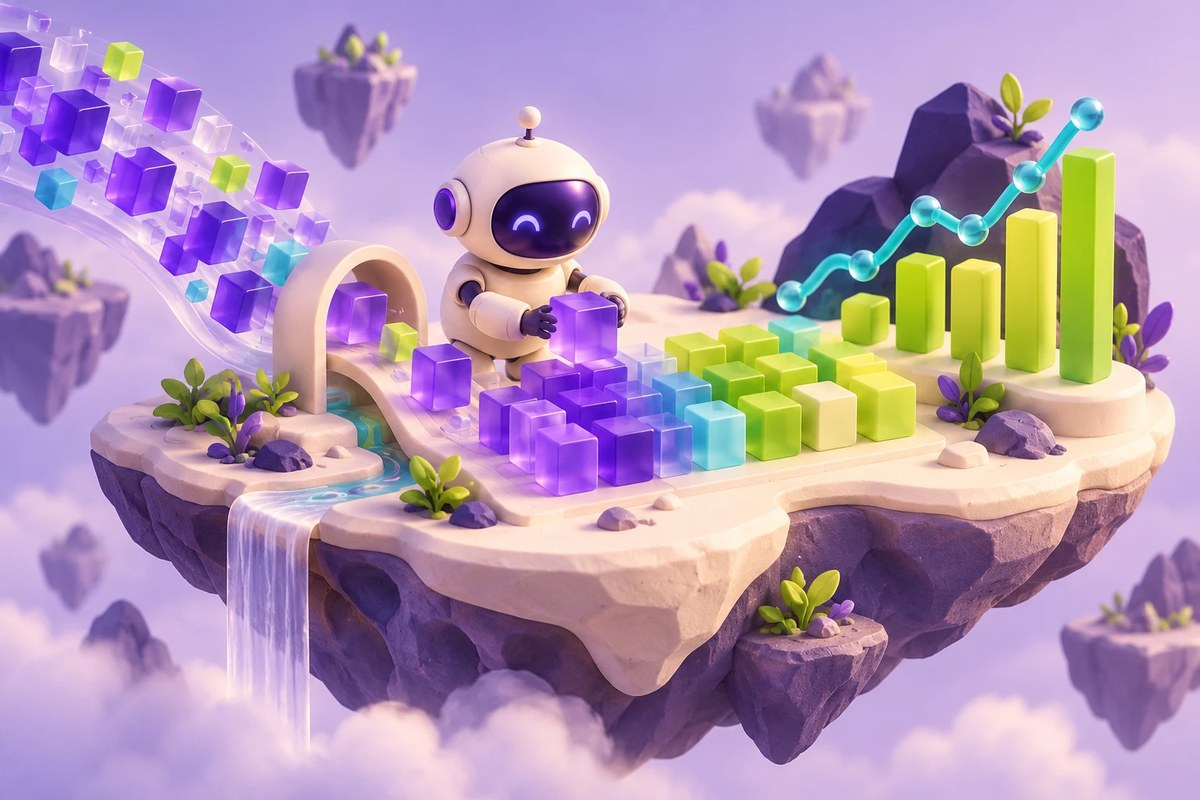

AI PATH · Python для машинного обучения · Урок 014

# Linux в Colab: файлы, данные и окружение

Базовый маршрут от ls до загрузки архивов и диагностики среды

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-014-goal"></a>
## Что вы разберёте

Научиться ориентироваться в виртуальной Linux-машине и проверять данные до обработки в Python.

### Перед началом

- Файл, каталог и путь
- Запуск ячеек Colab
- Различие локального компьютера и облачной машины

### Что понадобится

- Google Colab или отдельная Linux-среда с поддержкой IPython-команд !
- Каталог sample_data с California Housing и README
- Сетевой доступ для wget/git/pip и внешних архивов
- Для apt-get нужны права установки системных пакетов в учебной среде

## Навигация по уроку

- [Цель и подготовка](#ai-014-goal)
- [Карта урока](#ai-014-map)
- [Отличить shell от Python](#ai-014-section-01)
- [Посмотреть файл без лишнего вывода](#ai-014-section-02)
- [Понять относительный путь](#ai-014-section-03)
- [Создать отдельный проект](#ai-014-section-04)
- [Проверить результат скачивания](#ai-014-section-05)
- [Разобрать ZIP и tar.gz](#ai-014-section-06)
- [Различить pip, apt и git](#ai-014-section-07)
- [Снять фактический паспорт среды](#ai-014-section-08)
- [Проверьте понимание](#ai-014-practice)
- [Источники и ограничения](#ai-014-provenance)

<a id="ai-014-map"></a>
## Карта урока

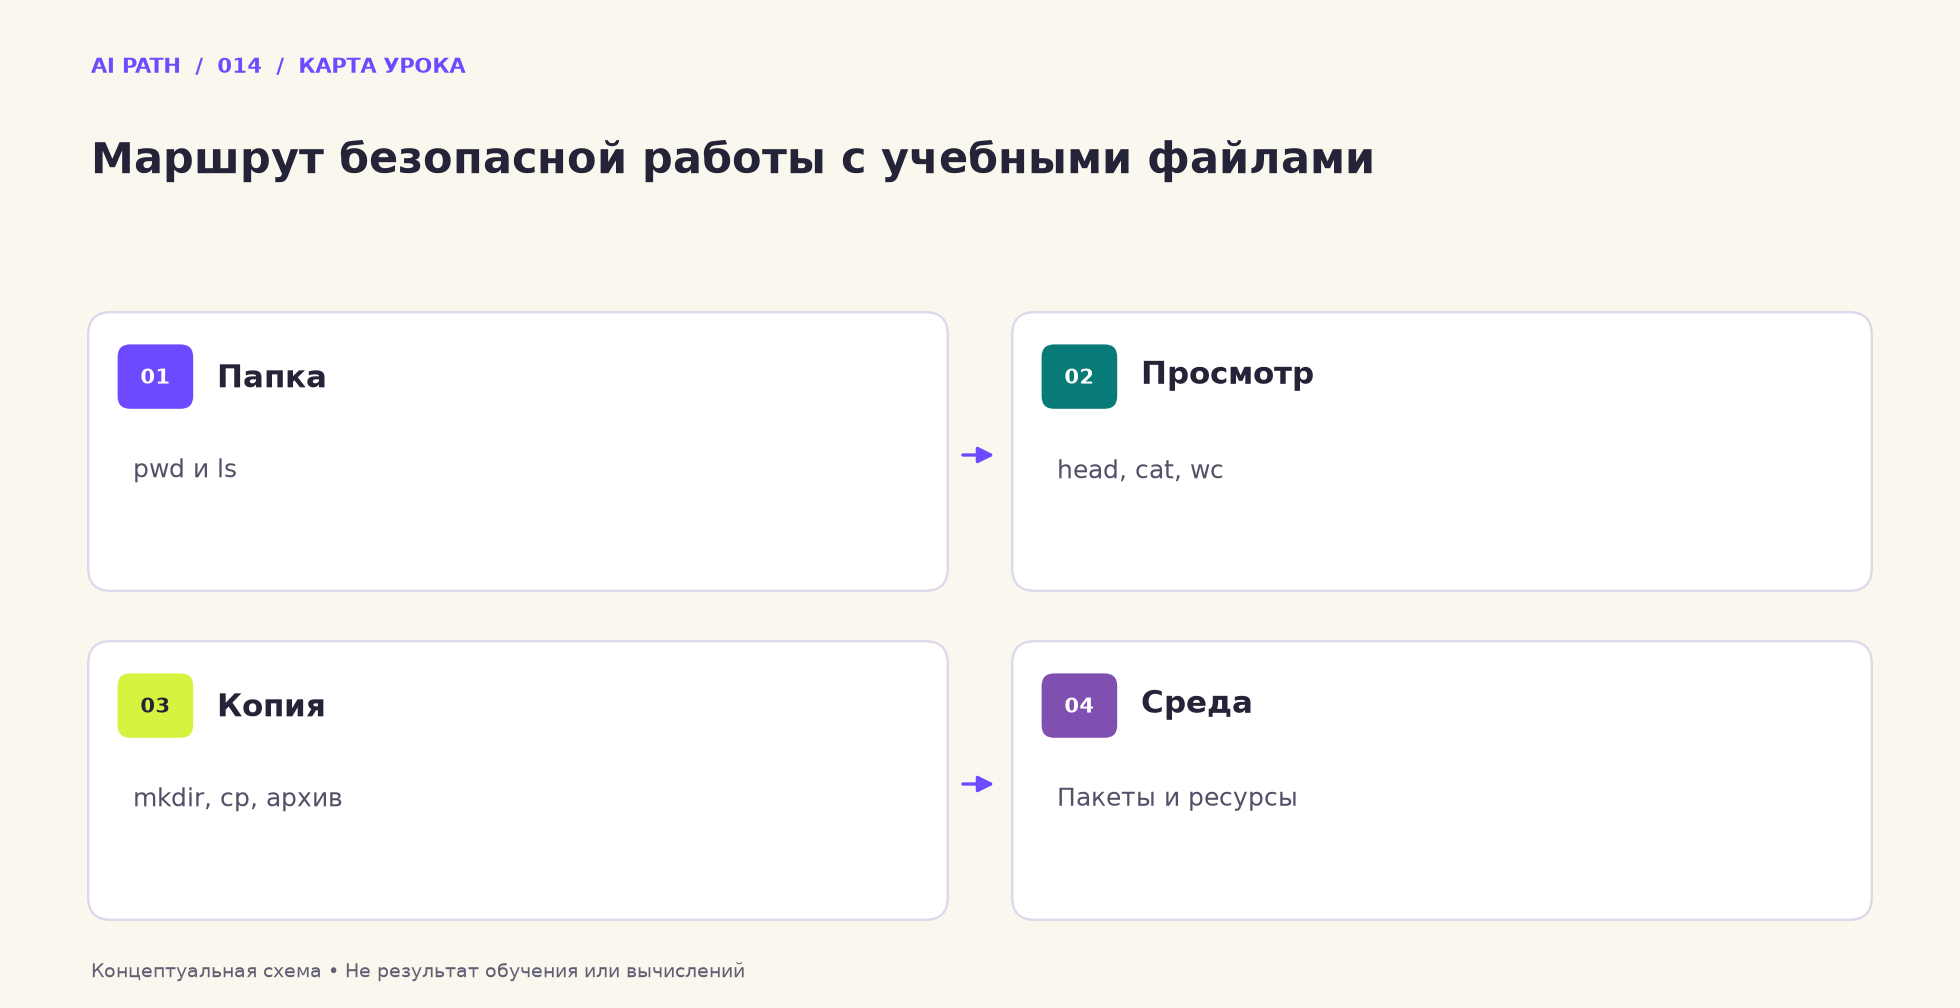

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Папка** — pwd и ls
2. **Просмотр** — head, cat, wc
3. **Копия** — mkdir, cp, архив
4. **Среда** — Пакеты и ресурсы

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/colab_linux.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Команды Linux на платформе Google Colaboratory

Код ноутбуков, которые мы создаем на платформе Google Colaboratory, запускается на виртуальной машине с Linux в облаке Google. Для большинства задач в Colaboratory достаточно средств Python, но иногда все-таки приходится использовать команды операционной системы. Например, для загрузки данных или установки пакетов Python. Если вы привыкли работать с Wndows, то использование команд Linux на первом этапе может вызвать затруднение.

В этом ноутбуке показаны примеры использования команд операционной системы Linux для выполнения часто встречающихся задач анализа данных на платформе Google Colaboratory

Чтобы запускать и редактировать код, сохраните копию этого ноутбука себе (File->Save a copy in Drive...). Свою копию вы сможете изменять и запускать.





<a id="ai-014-section-01"></a>
## 01 · Отличить shell от Python

Префикс ! передаёт команду Linux. Начните с ls и сравните текущий каталог с sample_data.

_Далее — исходные ячейки учебного материала._

## Основы использования командной строки в Colab

Комады Linux в ноутбуках Colaboratory должны начинаться с восклицательного знака (!). Именно по наличию восклицательного знака в начале строки определяется, что это не код Python, а команда операционной системы. 

Пример:

In [ ]:
!ls

sample_data


`ls` - команда для получения списка файлов в каталоге. Мы можем видеть, что в текущем каталоге есть всего один файл - `sample_data`. 

Но это на самом деле не файл, а каталог. Давайте посмотрим, что находится в нем.

In [ ]:
!ls sample_data

anscombe.json		      mnist_test.csv
california_housing_test.csv   mnist_train_small.csv
california_housing_train.csv  README.md


Если команде `ls` в качестве параметра указать имя каталога, то будет выведен список файлов в этом каталоге.

Каталог `sample_data`, как можно понять из названия, содержит демонстрационные данные. Этот каталог и данные в нем создаются автоматически при запуске виртуальной машины.

<a id="ai-014-section-02"></a>
## 02 · Посмотреть файл без лишнего вывода

head показывает начало, cat подходит небольшому README, wc -l считает строки. Выбирайте просмотр по размеру файла.

_Далее — исходные ячейки учебного материала._

## Просмотр файлов

Как узнать, что находится в файлах с демонстрационными данными? Можно написать код на Python, но быстрее использовать команды Linux. Команда `head` выводит первые строки указанного ей файла. 

In [ ]:
!head sample_data/california_housing_train.csv

"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-114.310000,34.190000,15.000000,5612.000000,1283.000000,1015.000000,472.000000,1.493600,66900.000000
-114.470000,34.400000,19.000000,7650.000000,1901.000000,1129.000000,463.000000,1.820000,80100.000000
-114.560000,33.690000,17.000000,720.000000,174.000000,333.000000,117.000000,1.650900,85700.000000
-114.570000,33.640000,14.000000,1501.000000,337.000000,515.000000,226.000000,3.191700,73400.000000
-114.570000,33.570000,20.000000,1454.000000,326.000000,624.000000,262.000000,1.925000,65500.000000
-114.580000,33.630000,29.000000,1387.000000,236.000000,671.000000,239.000000,3.343800,74000.000000
-114.580000,33.610000,25.000000,2907.000000,680.000000,1841.000000,633.000000,2.676800,82400.000000
-114.590000,34.830000,41.000000,812.000000,168.000000,375.000000,158.000000,1.708300,48500.000000
-114.590000,33.610000,34.000000,4789.000000,1175.000000,3134.000000

В первой строке файла файла `california_housing_train.csv` заголовок, а в остальных данные, разделенные запятыми.

По-умолчанию команда head выводит 10 строк из файла. Можно показать любое количество срок, использую параметр `-n`. Давайте выведем 15 строк:

In [ ]:
!head -n 15 sample_data/california_housing_train.csv

"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-114.310000,34.190000,15.000000,5612.000000,1283.000000,1015.000000,472.000000,1.493600,66900.000000
-114.470000,34.400000,19.000000,7650.000000,1901.000000,1129.000000,463.000000,1.820000,80100.000000
-114.560000,33.690000,17.000000,720.000000,174.000000,333.000000,117.000000,1.650900,85700.000000
-114.570000,33.640000,14.000000,1501.000000,337.000000,515.000000,226.000000,3.191700,73400.000000
-114.570000,33.570000,20.000000,1454.000000,326.000000,624.000000,262.000000,1.925000,65500.000000
-114.580000,33.630000,29.000000,1387.000000,236.000000,671.000000,239.000000,3.343800,74000.000000
-114.580000,33.610000,25.000000,2907.000000,680.000000,1841.000000,633.000000,2.676800,82400.000000
-114.590000,34.830000,41.000000,812.000000,168.000000,375.000000,158.000000,1.708300,48500.000000
-114.590000,33.610000,34.000000,4789.000000,1175.000000,3134.000000

Если хотим просмотреть весь файл, то можно использовать команду `cat`:

In [ ]:
!cat sample_data/README.md

This directory includes a few sample datasets to get you started.

* `california_housing_data*.csv` is California housing data from the 1990 US
  Census; more information is available at:
  https://developers.google.com/machine-learning/crash-course/california-housing-data-description

* `mnist_*.csv` is a small sample of the [MNIST
  database](https://en.wikipedia.org/wiki/MNIST_database), which is described
  at: http://yann.lecun.com/exdb/mnist/

* `anscombe.json` contains a copy of [Anscombe's
 quartet](https://en.wikipedia.org/wiki/Anscombe%27s_quartet);
  it was originally described in

      Anscombe, F. J. (1973). 'Graphs in Statistical Analysis'. American Statistician. 27 (1): 17-21. JSTOR 2682899.

  and our copy was prepared by the [vega_datasets library](https://github.com/altair-viz/vega_datasets/blob/4f67bdaad10f45e3549984e17e1b3088c731503d/vega_datasets/_data/anscombe.json).


Выводить весь файл стоит только если файл небольшой и мы сможем его посмотреть. Но как узнать, большой файл, или нет? Команда `wc -l` показывает количество срок в файле.

In [ ]:
!wc -l sample_data/README.md
!wc -l sample_data/california_housing_train.csv

17 sample_data/README.md
17001 sample_data/california_housing_train.csv


В файле `README.md` 17 строк, а в `california_housing_train.csv` - 17001. Выводить целиком файл `california_housing_train.csv` явно не стоит, он слишком большой.

Надеюсь вы обратили внимание, что в одной ячейке можно указывать не одну команду Linux, а несколько.

<a id="ai-014-section-03"></a>
## 03 · Понять относительный путь

Сравните ошибочный обратный слеш с корректным Linux-путём; pwd объясняет, относительно какой папки выполняется команда.

_Далее — исходные ячейки учебного материала._

## Каталоги и пути к файлам

В Linux для разделения имен файлов, каталогов и подкаталогов используется прямой слеш - `/` (в Windows для этой цели используется обратный слеш `\`). Python часто возволяет писать пути к файлам с любым типом слеша и автоматически конвертирует в понятный текущей операционной системе вариант. Но Linux так делать не умеет. Если вы попробуете использовать обратный слеш, как в Windows, то будет ошибка:

In [ ]:
!head sample_data\california_housing_train.csv

head: cannot open 'sample_datacalifornia_housing_train.csv' for reading: No such file or directory


In [ ]:
!head sample_data/california_housing_train.csv

"longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","median_house_value"
-114.310000,34.190000,15.000000,5612.000000,1283.000000,1015.000000,472.000000,1.493600,66900.000000
-114.470000,34.400000,19.000000,7650.000000,1901.000000,1129.000000,463.000000,1.820000,80100.000000
-114.560000,33.690000,17.000000,720.000000,174.000000,333.000000,117.000000,1.650900,85700.000000
-114.570000,33.640000,14.000000,1501.000000,337.000000,515.000000,226.000000,3.191700,73400.000000
-114.570000,33.570000,20.000000,1454.000000,326.000000,624.000000,262.000000,1.925000,65500.000000
-114.580000,33.630000,29.000000,1387.000000,236.000000,671.000000,239.000000,3.343800,74000.000000
-114.580000,33.610000,25.000000,2907.000000,680.000000,1841.000000,633.000000,2.676800,82400.000000
-114.590000,34.830000,41.000000,812.000000,168.000000,375.000000,158.000000,1.708300,48500.000000
-114.590000,33.610000,34.000000,4789.000000,1175.000000,3134.000000

До сих пор мы просматривали файлы в текущем каталоге. Но как узнать, где именно в файловой системе находится этот каталог? Для этой цели используется команда `pwd`:

In [ ]:
!pwd

/content


Путь к текущему каталогу - `/content`. В Linux нет разных дисков, все пути в файловой системе начинаются от так называемого корневого каталога, который обозначается прямым слешем - `/`.  Давайте посмотрим, какие есть каталоги верхнего уровня:

In [ ]:
!ls /

bin   content  dev  home  lib32  media	opt   root  sbin  swift  tmp	usr
boot  datalab  etc  lib   lib64  mnt	proc  run   srv   sys	 tools	var


Наиболее важные каталоги верхнего уровня:
- `bin`, `sbin` - исполняемые файлы
- `content` - каталог для данных, его мы уже рассматривали выше
- `home` - каталог для файлов пользователей ("домашний" каталог)
- `root` - домашний каталог для пользователя `root` (аналог Администратора в Linux)
- `lib`, `lib32`, `lib64` - библиотеки
- `tmp` - каталог для временных файлов
- `etc` - каталог с конфигурационными файлами

Потратьте некоторое время чтобы посмотреть содержимое этих каталогов.

В большей части этих каталогов мы не будем ничего менять. Нам нужно будет загружать файлы данных в каталог `content` и выполнять некоторые настройки в домашнем каталоге пользователя `root`.

<a id="ai-014-section-04"></a>
## 04 · Создать отдельный проект

mkdir и cp готовят рабочую копию California Housing. Убедитесь, что исходные sample_data остались на месте.

_Далее — исходные ячейки учебного материала._

## Копирование файлов и создание каталогов

Предположим, что мы решили создать проект, который использует демонстрационные данные Сalifornia Housing. Чтобы случайно не испортить исходные файлы, мы создадим отдельный каталог и скопируем файлы туда.

Создание каталога выполняется командой `mkdir`:

In [ ]:
!mkdir my_project

Проверим, что каталог создался:

In [ ]:
!ls

my_project  sample_data


Теперь скопируем в новый каталог демонстрационные данные. Для этого используется команда `cp`:

In [ ]:
!cp sample_data/california_housing_test.csv my_project  
!cp sample_data/california_housing_train.csv my_project  

Проверим, что файлы скопировались:

In [ ]:
!ls my_project/

california_housing_test.csv  california_housing_train.csv


<a id="ai-014-section-05"></a>
## 05 · Проверить результат скачивания

wget добавляет внешний CSV. Имя файла само по себе не подтверждает содержимое: посмотрите размер и первые строки.

_Далее — исходные ячейки учебного материала._

## Загрузка данных из интернет

Чаще всего нужные нам данные выложены в интернет и мы загружаем их на локальный компьютер через браузер. В Linux для загрузки файлов из интернет используется команда `wget`. Для примера давайте загрузим [данные о работе такси в Нью-Йорке](http://www.nyc.gov/html/tlc/html/about/trip_record_data.shtml).

In [ ]:
!wget https://s3.amazonaws.com/nyc-tlc/trip+data/yellow_tripdata_2018-06.csv

--2019-02-06 03:09:51--  https://s3.amazonaws.com/nyc-tlc/trip+data/yellow_tripdata_2018-06.csv
Resolving s3.amazonaws.com (s3.amazonaws.com)... 52.216.85.213
Connecting to s3.amazonaws.com (s3.amazonaws.com)|52.216.85.213|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 769389923 (734M) [text/csv]
Saving to: ‘yellow_tripdata_2018-06.csv’

yellow_tripdata_201 100%[===================>] 733.75M  36.7MB/s    in 21s     

2019-02-06 03:10:12 (35.5 MB/s) - ‘yellow_tripdata_2018-06.csv’ saved [769389923/769389923]



Проверим, что загруженный файл появился в текущем каталоге

In [ ]:
!ls

my_project  sample_data  yellow_tripdata_2018-06.csv


Просмотрим начало файла

In [ ]:
!head yellow_tripdata_2018-06.csv

VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount

1,2018-06-01 00:15:40,2018-06-01 00:16:46,1,.00,1,N,145,145,2,3,0.5,0.5,0,0,0.3,4.3
1,2018-06-01 00:04:18,2018-06-01 00:09:18,1,1.00,1,N,230,161,1,5.5,0.5,0.5,1.35,0,0.3,8.15
1,2018-06-01 00:14:39,2018-06-01 00:29:46,1,3.30,1,N,100,263,2,13,0.5,0.5,0,0,0.3,14.3
1,2018-06-01 00:51:25,2018-06-01 00:51:29,3,.00,1,N,145,145,2,2.5,0.5,0.5,0,0,0.3,3.8
1,2018-06-01 00:55:06,2018-06-01 00:55:10,1,.00,1,N,145,145,2,2.5,0.5,0.5,0,0,0.3,3.8
1,2018-06-01 00:09:00,2018-06-01 00:24:01,1,2.00,1,N,161,234,1,11.5,0.5,0.5,2.55,0,0.3,15.35
1,2018-06-01 00:02:33,2018-06-01 00:13:01,2,1.50,1,N,163,233,1,8.5,0.5,0.5,1.95,0,0.3,11.75
1,2018-06-01 00:13:23,2018-06-01 00:16:52,1,.70,1,N,186,246,1,5,0.5,0.5,1.85,0,0.3,8.15


<a id="ai-014-section-06"></a>
## 06 · Разобрать ZIP и tar.gz

Два архива показывают разные способы распаковки. Сначала проверьте файл и ожидаемый каталог, затем смотрите отдельное изображение LFW.

_Далее — исходные ячейки учебного материала._

## Архивы

Часто данные запакованы в архивы, чтобы занимать меньше места. Давайте посмотрим, как можно под Linux распаковывать архивы.

Начнем с простого - загрузим и распакуем данные в архиве `Zip`.  В качестве примера будем использовать небольшую часть набора данных  [Labeled Faces in the Wild](http://vis-www.cs.umass.edu/lfw/#download) - фотографии людей, чьи имена начинаются на A.

In [ ]:
!wget http://vis-www.cs.umass.edu/lfw/lfw-a.zip

--2019-02-06 03:12:30--  http://vis-www.cs.umass.edu/lfw/lfw-a.zip
Resolving vis-www.cs.umass.edu (vis-www.cs.umass.edu)... 128.119.244.95
Connecting to vis-www.cs.umass.edu (vis-www.cs.umass.edu)|128.119.244.95|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15167852 (14M) [application/zip]
Saving to: ‘lfw-a.zip’

lfw-a.zip           100%[===================>]  14.46M  6.07MB/s    in 2.4s    

2019-02-06 03:12:33 (6.07 MB/s) - ‘lfw-a.zip’ saved [15167852/15167852]



Распаковываем архив с помощью команды `unzip`:

In [ ]:
!unzip lfw-a.zip

Archive:  lfw-a.zip
   creating: lfw/Aaron_Eckhart/
  inflating: lfw/Aaron_Eckhart/Aaron_Eckhart_0001.jpg  
   creating: lfw/Aaron_Guiel/
  inflating: lfw/Aaron_Guiel/Aaron_Guiel_0001.jpg  
   creating: lfw/Aaron_Patterson/
  inflating: lfw/Aaron_Patterson/Aaron_Patterson_0001.jpg  
   creating: lfw/Aaron_Peirsol/
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0001.jpg  
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0002.jpg  
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0003.jpg  
  inflating: lfw/Aaron_Peirsol/Aaron_Peirsol_0004.jpg  
   creating: lfw/Aaron_Pena/
  inflating: lfw/Aaron_Pena/Aaron_Pena_0001.jpg  
   creating: lfw/Aaron_Sorkin/
  inflating: lfw/Aaron_Sorkin/Aaron_Sorkin_0001.jpg  
  inflating: lfw/Aaron_Sorkin/Aaron_Sorkin_0002.jpg  
   creating: lfw/Aaron_Tippin/
  inflating: lfw/Aaron_Tippin/Aaron_Tippin_0001.jpg  
   creating: lfw/Abba_Eban/
  inflating: lfw/Abba_Eban/Abba_Eban_0001.jpg  
   creating: lfw/Abbas_Kiarostami/
  inflating: lfw/Abbas_Kiarostami/Abbas_Kiaros

Проверяем результаты распаковки

In [ ]:
!ls lfw

Aaron_Eckhart		      Amanda_Coetzer
Aaron_Guiel		      Amanda_Marsh
Aaron_Patterson		      Amanda_Plumer
Aaron_Peirsol		      Amber_Frey
Aaron_Pena		      Amber_Tamblyn
Aaron_Sorkin		      Ambrose_Lee
Aaron_Tippin		      Amelia_Vega
Abba_Eban		      Amelie_Mauresmo
Abbas_Kiarostami	      Amer_al-Saadi
Abdel_Aziz_Al-Hakim	      Amporn_Falise
Abdel_Madi_Shabneh	      Amram_Mitzna
Abdel_Nasser_Assidi	      Amr_Moussa
Abdoulaye_Wade		      Amy_Brenneman
Abdulaziz_Kamilov	      Amy_Cotton
Abdullah		      Amy_Gale
Abdullah_Ahmad_Badawi	      Amy_Pascal
Abdullah_al-Attiyah	      Amy_Redford
Abdullah_Gul		      Amy_Smart
Abdullah_Nasseef	      Amy_Yasbeck
Abdullatif_Sener	      Ana_Claudia_Talancon
Abdul_Majeed_Shobokshi	      Ana_Guevara
Abdul_Rahman		      Ana_Isabel_Sanchez
Abel_Aguilar		      Ana_Palacio
Abel_Pacheco		      Ana_Paula_Gerard
Abid_Hamid_Mahmud_Al-Tikriti  Ana_Sebastiao
Abner_Martinez		      Anastasia_Kelesidou
Abraham_Foxman		      Anastasia_Myskina
Aby_Har-Even		      Anato

In [ ]:
!ls lfw/Angelina_Jolie

Angelina_Jolie_0001.jpg  Angelina_Jolie_0008.jpg  Angelina_Jolie_0015.jpg
Angelina_Jolie_0002.jpg  Angelina_Jolie_0009.jpg  Angelina_Jolie_0016.jpg
Angelina_Jolie_0003.jpg  Angelina_Jolie_0010.jpg  Angelina_Jolie_0017.jpg
Angelina_Jolie_0004.jpg  Angelina_Jolie_0011.jpg  Angelina_Jolie_0018.jpg
Angelina_Jolie_0005.jpg  Angelina_Jolie_0012.jpg  Angelina_Jolie_0019.jpg
Angelina_Jolie_0006.jpg  Angelina_Jolie_0013.jpg  Angelina_Jolie_0020.jpg
Angelina_Jolie_0007.jpg  Angelina_Jolie_0014.jpg


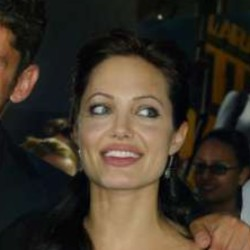

In [ ]:
from IPython.display import Image
Image('lfw/Angelina_Jolie/Angelina_Jolie_0004.jpg')

Более сложный вариант - архив в формате `tar`, сжатый архиватором `gzip`. Такие файлы имеют расширение `.tar.gz` (или `.tgz`). В Linux такой формат архивов более популярен, чем `zip`. Именно в таком виде распространяются предварительно обученные модели TensorFlow. 

Давайте загрузим модель TensorFlow для обнаружения объектов на изображениях и распакуем её. Загружаем модель с помощью `wget`:

In [ ]:
!wget http://download.tensorflow.org/models/object_detection/faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz

--2020-01-05 16:28:07--  http://download.tensorflow.org/models/object_detection/faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz
Resolving download.tensorflow.org (download.tensorflow.org)... 108.177.127.128, 2a00:1450:4013:c07::80
Connecting to download.tensorflow.org (download.tensorflow.org)|108.177.127.128|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 672221478 (641M) [application/x-tar]
Saving to: ‘faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz’

faster_rcnn_incepti 100%[===================>] 641.08M   171MB/s    in 3.8s    

2020-01-05 16:28:16 (171 MB/s) - ‘faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz’ saved [672221478/672221478]



Распаковываем архив:

In [ ]:
!tar xvfz faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28.tar.gz

faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/model.ckpt.index
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/checkpoint
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/pipeline.config
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/model.ckpt.data-00000-of-00001
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/model.ckpt.meta
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/saved_model/
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/saved_model/saved_model.pb
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/saved_model/variables/
faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28/frozen_inference_graph.pb


Проверяем распакованное содержимое архива:

In [ ]:
!ls faster_rcnn_inception_resnet_v2_atrous_coco_2018_01_28

checkpoint			model.ckpt.index  saved_model
frozen_inference_graph.pb	model.ckpt.meta
model.ckpt.data-00000-of-00001	pipeline.config


<a id="ai-014-section-07"></a>
## 07 · Различить pip, apt и git

Эти команды устанавливают Python-пакет, системную библиотеку и копируют репозиторий. Выполняйте их в выделенной учебной среде.

_Далее — исходные ячейки учебного материала._

## Установка пакетов

На colaboratory уже установлено много полезных пакетов Python для машинного обучения и других задач. Но если вам понадобился какой-то новый пакет, то его можно достаточно просто установить с помощью команды `pip`. Например, установим библиотеку [`mxnet`](https://mxnet.apache.org):

In [ ]:
!pip install mxnet

    100% |████████████████████████████████| 27.1MB 1.7MB/s 
    100% |████████████████████████████████| 61kB 23.7MB/s 
spacy 2.0.18 has requirement numpy>=1.15.0, but you'll have numpy 1.14.6 which is incompatible.
google-colab 0.0.1a1 has requirement requests~=2.18.0, but you'll have requests 2.21.0 which is incompatible.
cufflinks 0.14.6 has requirement plotly>=3.0.0, but you'll have plotly 1.12.12 which is incompatible.
  Found existing installation: graphviz 0.10.1
    Uninstalling graphviz-0.10.1:
      Successfully uninstalled graphviz-0.10.1
  Found existing installation: requests 2.18.4
    Uninstalling requests-2.18.4:
      Successfully uninstalled requests-2.18.4


Также иногда может понадобиться установка пакетов операционной системы. Например, библиотеку для работы с архивами в разных форматах [libarchive](https://www.libarchive.org/). Системные пакеты устанавливаются командой `apt-get`:

In [ ]:
!apt-get install libarchive-dev -y

Reading package lists... Done
Building dependency tree       
Reading state information... Done
The following NEW packages will be installed:
  libarchive-dev
0 upgraded, 1 newly installed, 0 to remove and 3 not upgraded.
Need to get 470 kB of archives.
After this operation, 1,621 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu bionic-updates/main amd64 libarchive-dev amd64 3.2.2-3.1ubuntu0.2 [470 kB]
Fetched 470 kB in 1s (681 kB/s)
Selecting previously unselected package libarchive-dev:amd64.
(Reading database ... 111313 files and directories currently installed.)
Preparing to unpack .../libarchive-dev_3.2.2-3.1ubuntu0.2_amd64.deb ...
Unpacking libarchive-dev:amd64 (3.2.2-3.1ubuntu0.2) ...
Processing triggers for man-db (2.8.3-2ubuntu0.1) ...
Setting up libarchive-dev:amd64 (3.2.2-3.1ubuntu0.2) ...


## Работа с Git

В Colaboratory можно использовать обычные команды `Git`. Например, склонируем репозиторий с моделями `TensorFlow`:

In [ ]:
!git clone https://github.com/tensorflow/models.git

Cloning into 'models'...
remote: Enumerating objects: 33544, done.
remote: Total 33544 (delta 0), reused 0 (delta 0), pack-reused 33544
Receiving objects: 100% (33544/33544), 511.89 MiB | 35.75 MiB/s, done.
Resolving deltas: 100% (21458/21458), done.
Checking out files: 100% (3194/3194), done.


Проверяем

In [ ]:
!ls models

AUTHORS     CONTRIBUTING.md    LICENSE	 README.md  samples    WORKSPACE
CODEOWNERS  ISSUE_TEMPLATE.md  official  research   tutorials


In [ ]:
!cat models/README.md

# TensorFlow Models

This repository contains a number of different models implemented in [TensorFlow](https://www.tensorflow.org):

The [official models](official) are a collection of example models that use TensorFlow's high-level APIs. They are intended to be well-maintained, tested, and kept up to date with the latest stable TensorFlow API. They should also be reasonably optimized for fast performance while still being easy to read. We especially recommend newer TensorFlow users to start here.

The [research models](https://github.com/tensorflow/models/tree/master/research) are a large collection of models implemented in TensorFlow by researchers. They are not officially supported or available in release branches; it is up to the individual researchers to maintain the models and/or provide support on issues and pull requests.

The [samples folder](samples) contains code snippets and smaller models that demonstrate features of TensorFlow, including code presented in various blog pos

<a id="ai-014-section-08"></a>
## 08 · Снять фактический паспорт среды

Версия Linux, CPU, память, GPU и пользователь определяются командами заново. Числа в старом тексте не описывают вашу текущую машину.

_Далее — исходные ячейки учебного материала._

## Какой Linux используется в Colaboratory?



In [ ]:
!lsb_release -a 

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 18.04.3 LTS
Release:	18.04
Codename:	bionic


## Сколько процесоров и памяти?

**Процессоры**

In [ ]:
!cat /proc/cpuinfo

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 85
model name	: Intel(R) Xeon(R) CPU @ 2.00GHz
stepping	: 3
microcode	: 0x1
cpu MHz		: 2000.172
cache size	: 39424 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch invpcid_single ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm mpx avx512f avx512dq rdseed adx smap clflushopt clwb avx512cd avx512bw avx512vl xsaveopt xsavec xgetbv1 xsaves arat md_clear arch_capabilities
bugs		: cpu_meltdown spectre_v1 spectre_v2 spec_store_bypass l1tf mds swapgs
bogomips	: 400

Количество процессоров 2, но это означает не два процессора, а два ядра. Производитель процессоров Intel, тактовая частота 2,3 ГГц.

Если есть желание, можете подробнее разобрать информацию из `cpuinfo`, можно найти много интересного. Рекомендую начать с раздела `bugs`.



**Память**

In [ ]:
!free -h

              total        used        free      shared  buff/cache   available
Mem:            12G        564M        5.4G        896K        6.8G         11G
Swap:            0B          0B          0B


Всего памяти 12 ГБ, из них свободно 10ГБ.

## Какой GPU используется?

Если вы подключили GPU в разделе Runtime -> Change Runtime Type -> Hardware accelerator, то модель можно посмотреть следующей командой: 

In [ ]:
!cat /proc/driver/nvidia/gpus/0000:00:04.0/information

Model: 		 Tesla P100-PCIE-16GB
IRQ:   		 35
GPU UUID: 	 GPU-62307fea-9c30-d83b-1eba-4053f25bb152
Video BIOS: 	 86.00.4d.00.01
Bus Type: 	 PCI
DMA Size: 	 47 bits
DMA Mask: 	 0x7fffffffffff
Bus Location: 	 0000:00:04.0
Device Minor: 	 0
Blacklisted:	 No


In [ ]:
!ls /proc/driver/nvidia/gpus/

0000:00:04.0


## Под каким пользователем Linux выполняются команды в Colaboratory?

In [ ]:
!whoami

root


Имя пользователя - `root`, суперпользователь. Домашний каталог пользователя - `/root`

<a id="ai-014-practice"></a>
## Проверьте понимание

1. Объясните, почему путь с обратным слешем не совпал с нужным Linux-файлом.
2. Проверьте, что копии CSV появились в my_project, а оригиналы сохранились.
3. Сравните фактические CPU/память/GPU с архивными комментариями без переноса старых чисел.

### Один самостоятельный эксперимент

Создайте отдельную учебную папку, скопируйте один CSV из sample_data и сопоставьте первые строки, число строк и контрольную сумму копии с оригиналом.

**Критерий успеха:** Файл скопирован без изменения содержимого; различие между путём источника и назначения объяснено; тяжёлые внешние загрузки не нужны.

<a id="ai-014-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Linux/colab_linux.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Команды рассчитаны на Linux/Colab, а не на Windows PowerShell.
- Ссылки на такси 2018 года, LFW и модель TensorFlow внешние и могут быть недоступны; новый сетевой запуск не выполнен.
- pip/apt изменяют окружение; исходник не закрепляет все версии пакетов.
- GPU-путь с конкретным PCI-адресом не универсален; старые сведения о CPU, памяти и root — исторический снимок.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.